# Chronic Kidney Disease Prediction Pipeline (Final Updated)
**Includes stratified splitting for all classes and uses `.keras` model saving format.**
Steps:
1. Imports & Setup
2. Data Loading & Cleaning
3. Advanced Imputation (MICE)
4. Export Imputed Dataset
5. Encoding & Scaling & Stratified Split
6. RFE Feature Selection
7. Neural Network Training & Evaluation
8. Exporting Results (including `.keras` format)
9. Visualization


### Repository setup
This repository version uses the files under `data/` directly. The original Colab Drive mount has been removed for portability.


In [5]:
# Step 1: Imports & Setup
import warnings
warnings.filterwarnings('ignore')

import logging
logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')

import pandas as pd
import numpy as np
from google.colab import files

# sklearn
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, LabelEncoder
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import BayesianRidge, LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
from sklearn.metrics import classification_report, accuracy_score

# TensorFlow/Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout


In [8]:
# Step 2: Load & Clean Data
#uploaded = files.upload()  # Upload kidney_disease.csv
df = pd.read_csv('/content/drive/MyDrive/CKD/kidney_disease.csv')
df



,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395,55.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,...,47,6700,4.9,no,no,no,good,no,no,notckd
396,396,42.0,70.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,54,7800,6.2,no,no,no,good,no,no,notckd
397,397,12.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,...,49,6600,5.4,no,no,no,good,no,no,notckd
398,398,17.0,60.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,51,7200,5.9,no,no,no,good,no,no,notckd


In [ ]:
# Step 3: Advanced Imputation (MICE)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

num_imp = IterativeImputer(estimator=BayesianRidge(), max_iter=30, random_state=42)
df[numeric_cols] = num_imp.fit_transform(df[numeric_cols])

cat_enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
df[categorical_cols] = cat_enc.fit_transform(df[categorical_cols].astype(str))

cat_imp = IterativeImputer(
    estimator=RandomForestClassifier(n_estimators=20, random_state=42),
    max_iter=30, initial_strategy='most_frequent', random_state=42
)
df[categorical_cols] = np.round(cat_imp.fit_transform(df[categorical_cols]))
df[categorical_cols] = cat_enc.inverse_transform(df[categorical_cols])

print('Missing values after imputation:')
print(df.isnull().sum())


Missing values after imputation:
id                0
age               0
bp                0
sg                0
al                0
su                0
rbc               0
pc                0
pcc               0
ba                0
bgr               0
bu                0
sc                0
sod               0
pot               0
hemo              0
pcv               0
wc                0
rc                0
htn               0
dm                0
cad               0
appet             0
pe                0
ane               0
classification    0
dtype: int64


In [ ]:
# Step 4: Export Imputed Dataset
df.to_csv('kidney_disease_imputed.csv', index=False)
files.download('kidney_disease_imputed.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Step 5: Encode, Scale & Stratified Split
df_model = df.drop(columns=['id'], errors='ignore')

# Encode categoricals
cat_cols = df_model.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    df_model[col] = LabelEncoder().fit_transform(df_model[col])

X = df_model.drop(columns=['classification'])
y = df_model['classification'].astype(int)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)


In [ ]:
# Step 6: RFE Feature Selection
est = LogisticRegression(max_iter=1000, random_state=42)
selector = RFE(estimator=est, n_features_to_select=10, step=1)
selector.fit(X_train, y_train)

selected_features = X.columns[selector.support_]
print('Selected features:', list(selected_features))

X_train_sel = selector.transform(X_train)
X_test_sel = selector.transform(X_test)


Selected features: ['sg', 'al', 'rbc', 'bgr', 'hemo', 'htn', 'dm', 'appet', 'pe', 'ane']


In [ ]:
# Step 7: Build & Train Neural Network
cw = dict(enumerate(class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)))

model = Sequential([
    Input(shape=(X_train_sel.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

history = model.fit(
    X_train_sel, y_train,
    validation_data=(X_test_sel, y_test),
    epochs=30, batch_size=16,
    class_weight=cw
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,883 (11.26 KB)

 Trainable params: 2,883 (11.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.3895 - loss: 1.1327 - val_accuracy: 0.9125 - val_loss: 0.6510
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8205 - loss: 1.0310 - val_accuracy: 0.9375 - val_loss: 0.4237
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9312 - loss: 0.6951 - val_accuracy: 0.9375 - val_loss: 0.3009
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9282 - loss: 0.6562 - val_accuracy: 0.9500 - val_loss: 0.2273
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9394 - loss: 1.2956 - val_accuracy: 0.9625 - val_loss: 0.1698
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9676 - loss: 0.2884 - val_accuracy: 0.9750 - val_loss: 0.1310
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9602 - loss: 0.2512 - val_accuracy: 0.9625 - val_loss: 0.1348
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9548 - loss: 0.6977 - val_accuracy: 0.9625 - val_loss

In [ ]:
# Step 8: Evaluate & Export Results
y_pred = np.argmax(model.predict(X_test_sel), axis=1)

print(classification_report(y_test, y_pred, zero_division=0))
print('Accuracy:', accuracy_score(y_test, y_pred))

# Export predictions
out_df = pd.DataFrame(X_test_sel, columns=selected_features)
out_df['actual'] = y_test
out_df['predicted'] = y_pred
out_df.to_csv('predictions.csv', index=False)
files.download('predictions.csv')

# Save model in native Keras format
model.save('kidney_model.keras')
files.download('kidney_model.keras')

# Save report
with open('classification_report.txt', 'w') as f:
    f.write(classification_report(y_test, y_pred))
files.download('classification_report.txt')


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        50
           1       0.00      0.00      0.00         0
           2       1.00      1.00      1.00        30

    accuracy                           0.99        80
   macro avg       0.67      0.66      0.66        80
weighted avg       1.00      0.99      0.99        80

Accuracy: 0.9875


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

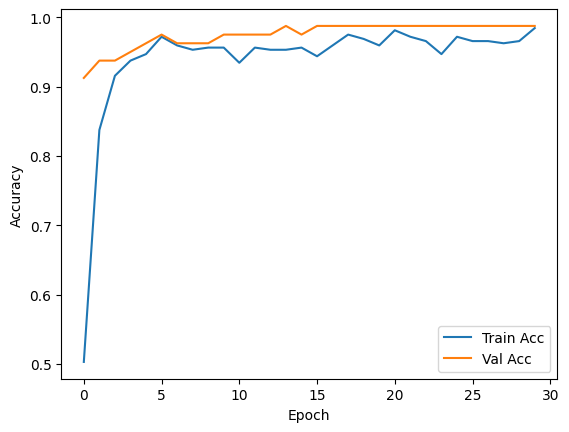

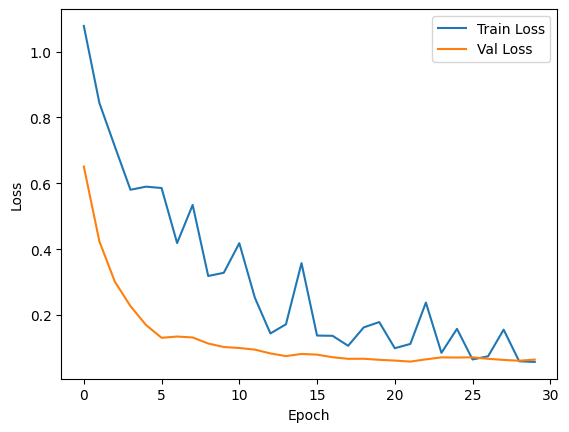

In [ ]:
# Step 9: Plot Training History
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.show()
